# Plotting geospatial data with git branching

This week you will wrangle data about earthquakes and collaborate with a partner using git branches. In this discussion section, you will:

Break down a question into accessible data wrangling steps
Import and plot different types of geospatial data
Practice git branching and pull requests with a partner

In [1]:
# Load packages

import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
# Load data

boundaries = gpd.read_file('/Users/courtneylorey/Desktop/GitHub/eds220/earthquake-branching/data/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')
earthquake = pd.read_csv('/Users/courtneylorey/Desktop/GitHub/eds220/earthquake-branching/data/earthquake_data.csv')

In [ ]:
# Explore data
boundaries.dtypes
earthquake.dtypes
print(type(boundaries.geometry))
boundaries.crs


<class 'geopandas.geoseries.GeoSeries'>


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [4]:
# Create points from latitude and longitude
points = gpd.points_from_xy(earthquake['longitude'],
earthquake['latitude'])
print(points)

# Create geodataframe
geo_earthquakes = gpd.GeoDataFrame(earthquake, # Data
geometry=points, # Specify geometry column
crs='EPSG:4326' # Specify CRS
)

<GeometryArray>
[ <POINT (-152.708 60.252)>,   <POINT (-115.131 37.07)>,
  <POINT (-149.253 64.672)>,  <POINT (-148.958 63.189)>,
  <POINT (-115.692 32.617)>,  <POINT (-117.014 32.568)>,
   <POINT (-116.36 33.359)>,    <POINT (-150.696 62.8)>,
   <POINT (-151.992 58.17)>,  <POINT (-121.729 37.686)>,
 ...
     <POINT (71.946 37.21)>,   <POINT (-148.224 63.48)>,
 <POINT (-179.602 -24.634)>,   <POINT (-149.017 65.16)>,
  <POINT (-150.388 62.796)>,  <POINT (-146.763 60.964)>,
  <POINT (-154.416 58.869)>,  <POINT (-122.826 38.843)>,
  <POINT (-148.992 65.152)>,  <POINT (-147.024 60.227)>]
Length: 120108, dtype: geometry


In [5]:
# Check that CRS matches
print(boundaries.crs)
print(geo_earthquakes.crs)

EPSG:4326
EPSG:4326


In [6]:
# Prelim plot

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add earthquake point plot to our figure's axes
geo_earthquakes.plot(ax=ax, # add plot to specific axes
                 alpha=0.3, # control transparency
                 color='brown') # update point color

# Add boundary 
boundaries.plot(ax=ax,
                 alpha=0.5)

# Update axes
ax.set_title('Global Earthquakes')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Adding caption
plt.figtext(0.5, -0.05, 'Caption is here!', horizontalalignment = 'center', wrap = True)

# Display figure
plt.show()

<Figure size 640x480 with 1 Axes>

In [ ]:
# Convert to datetime, filter for year and magnitude 
geo_earthquakes['time'] = pd.to_datetime(geo_earthquakes['time'])
geo_earthquakes['year'] = geo_earthquakes['time'].dt.year
filter_eqk = geo_earthquakes[(geo_earthquakes['year'] == 2014) & (geo_earthquakes['mag'] >= 6.5)]



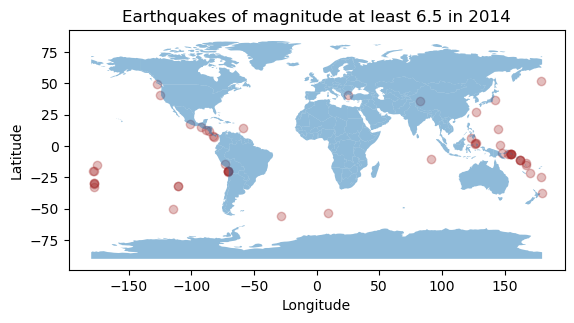

In [11]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add earthquake point plot to our figure's axes
filter_eqk.plot(ax=ax, # add plot to specific axes
                 alpha=0.3, # control transparency
                 color='brown') # update point color

# Add boundary 
boundaries.plot(ax=ax,
                 alpha=0.5)

# Update axes
ax.set_title('Earthquakes of magnitude at least 6.5 in 2014')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Display figure
plt.show()